<a href="https://colab.research.google.com/github/priyadarshan189/Healthcare-Analytics-for-Doctor-Visits/blob/main/Healthcare_Analytics_Doctor_Visits_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Healthcare Analytics for Doctor Visits
**AICTE STU ID:** STU6822a2f4ab1af1747100404

This notebook performs an exploratory data analysis (EDA) on a patient-level health survey dataset to understand what drives the frequency of doctor visits, including the roles of chronic illness, insurance coverage, gender, age and general health.

**How to run in Google Colab:**
1. Open this notebook in Google Colab (`File -> Upload notebook` or drag-and-drop).
2. Run the first code cell and upload `P2-Healthcare_Analytics_for_Doctor_Visits.csv` when prompted (or place the CSV in the same Colab session and keep the filename as-is).
3. Run all cells in order (`Runtime -> Run all`).


## 1. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11


## 2. Load the Dataset
Upload the CSV file using the file picker below (Colab only).

In [3]:
# Uncomment the following lines if running in Google Colab and need to upload the file
# from google.colab import files
# uploaded = files.upload()
# csv_filename = list(uploaded.keys())[0]

# If the CSV is already in your Colab working directory, just set the filename directly:
csv_filename = "/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv"

df = pd.read_csv(csv_filename, index_col=0)
df.head()


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


## 3. Column Reference

This dataset comes from an Australian health survey. Key columns:

| Column | Meaning |
|---|---|
| `visits` | Number of doctor visits in the past 2 weeks |
| `gender` | Patient gender |
| `age` | Age / 100 (e.g. 0.19 = 19 years old) |
| `income` | Annual income, scaled |
| `illness` | Number of illnesses in the past 2 weeks (0-5) |
| `reduced` | Number of days of reduced activity due to illness |
| `health` | General health questionnaire score (0-12, higher = worse) |
| `private` | Has private health insurance (yes/no) |
| `freepoor` | Free government insurance due to low income (yes/no) |
| `freerepat` | Free government insurance due to age/disability/veteran status (yes/no) |
| `nchronic` | Has a chronic condition that does NOT limit activity (yes/no) |
| `lchronic` | Has a chronic condition that DOES limit activity (yes/no) |


## 4. Data Overview & Cleaning

In [4]:
print("Shape:", df.shape)
print("\nColumn Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())


Shape: (5190, 12)

Column Data Types:
visits         int64
gender        object
age          float64
income       float64
illness        int64
reduced        int64
health         int64
private       object
freepoor      object
freerepat     object
nchronic      object
lchronic      object
dtype: object

Missing Values:
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64

Duplicate Rows: 1320


In [ ]:
df.describe()


No missing values or major data quality issues were found in this dataset (5,190 patient records, 12 columns).

## 5. Feature Engineering
Convert the scaled `age` column back into actual years for easier interpretation.

In [ ]:
df["age_years"] = (df["age"] * 100).round().astype(int)
df[["age", "age_years"]].head()


## 6. Exploratory Data Analysis

### 6.1 Distribution of Doctor Visits

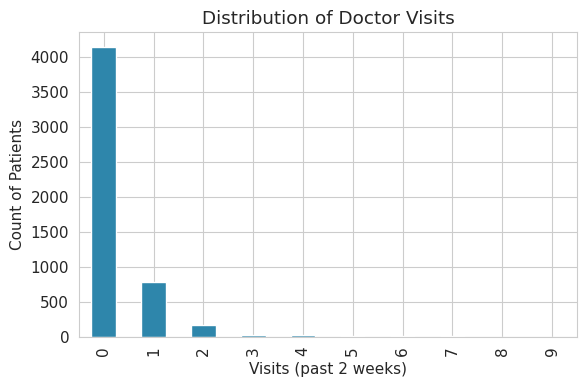

Percent of patients with zero visits: 79.8%


In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
df["visits"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#2E86AB")
ax.set_title("Distribution of Doctor Visits")
ax.set_xlabel("Visits (past 2 weeks)")
ax.set_ylabel("Count of Patients")
plt.tight_layout()
plt.show()

zero_pct = 100 * (df["visits"] == 0).mean()
print(f"Percent of patients with zero visits: {zero_pct:.1f}%")


### 6.2 Average Visits by Limiting Chronic Illness

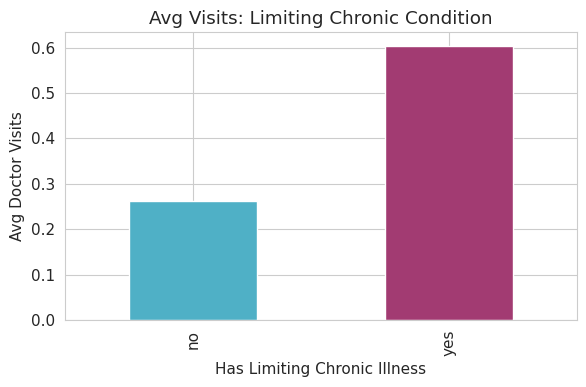

lchronic
no     0.261941
yes    0.603306
Name: visits, dtype: float64


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
df.groupby("lchronic")["visits"].mean().reindex(["no", "yes"]).plot(
    kind="bar", ax=ax, color=["#4FB0C6", "#A23B72"]
)
ax.set_title("Avg Visits: Limiting Chronic Condition")
ax.set_xlabel("Has Limiting Chronic Illness")
ax.set_ylabel("Avg Doctor Visits")
plt.tight_layout()
plt.show()

print(df.groupby("lchronic")["visits"].mean())


### 6.3 Average Visits by Gender

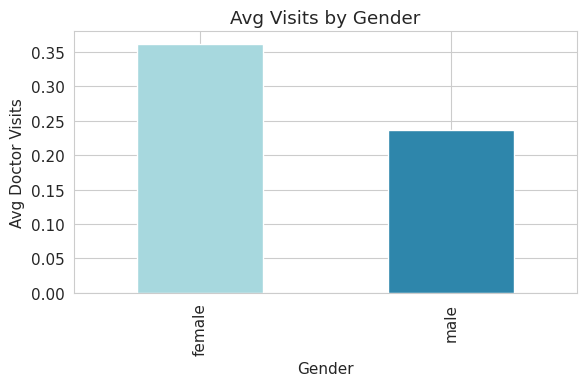

gender
female    0.361954
male      0.236334
Name: visits, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
df.groupby("gender")["visits"].mean().plot(kind="bar", ax=ax, color=["#A7D8DE", "#2E86AB"])
ax.set_title("Avg Visits by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Avg Doctor Visits")
plt.tight_layout()
plt.show()

print(df.groupby("gender")["visits"].mean())


### 6.4 Visits by Insurance Type

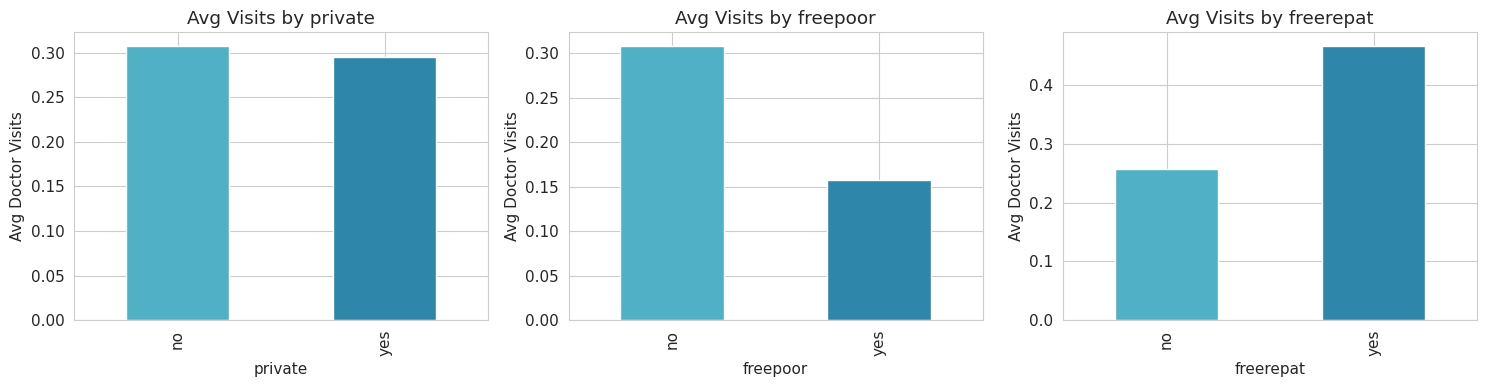

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["private", "freepoor", "freerepat"]):
    df.groupby(col)["visits"].mean().reindex(["no", "yes"]).plot(
        kind="bar", ax=ax, color=["#4FB0C6", "#2E86AB"]
    )
    ax.set_title(f"Avg Visits by {col}")
    ax.set_ylabel("Avg Doctor Visits")

plt.tight_layout()
plt.show()


### 6.5 Visits vs Reduced-Activity Days & Health Score

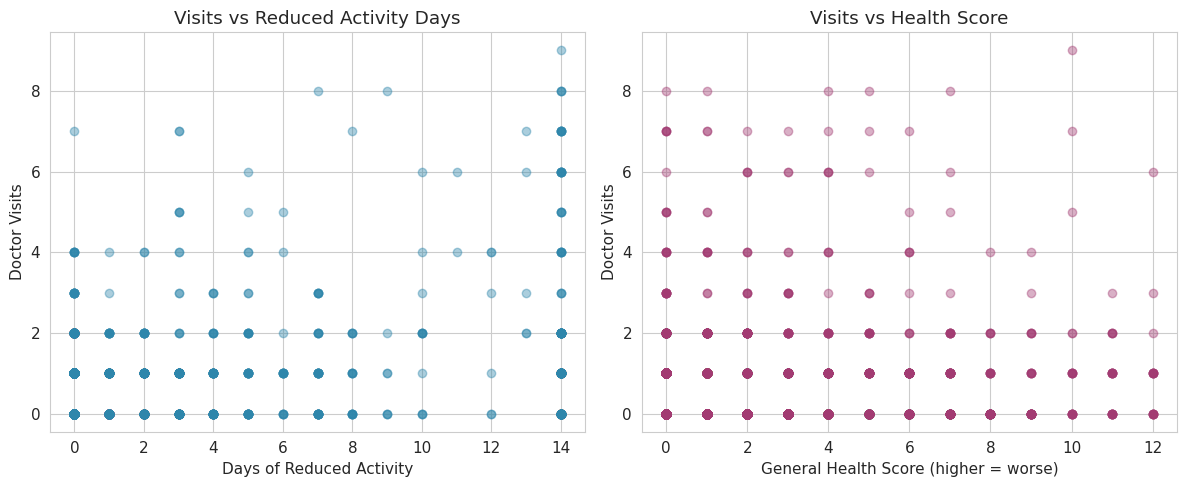

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df["reduced"], df["visits"], alpha=0.4, color="#2E86AB")
axes[0].set_xlabel("Days of Reduced Activity")
axes[0].set_ylabel("Doctor Visits")
axes[0].set_title("Visits vs Reduced Activity Days")

axes[1].scatter(df["health"], df["visits"], alpha=0.4, color="#A23B72")
axes[1].set_xlabel("General Health Score (higher = worse)")
axes[1].set_ylabel("Doctor Visits")
axes[1].set_title("Visits vs Health Score")

plt.tight_layout()
plt.show()


### 6.6 Correlation Heatmap

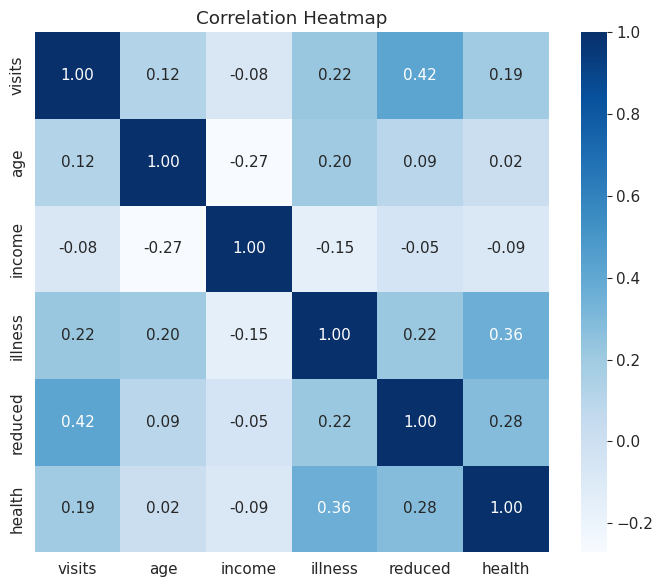

In [9]:
numeric_cols = ["visits", "age", "income", "illness", "reduced", "health"]
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 7. Key Findings

Run the cell below to print a summary of the key statistics used on the Results slide.

In [10]:
print("KEY FINDINGS")
print("=" * 50)
print(f"Total patient records analyzed: {len(df)}")
print(f"Percent with zero doctor visits: {100 * (df['visits'] == 0).mean():.1f}%")
print()
print("Average visits by limiting chronic illness:")
print(df.groupby("lchronic")["visits"].mean())
print()
print("Average visits by gender:")
print(df.groupby("gender")["visits"].mean())
print()
print(f"Correlation (reduced activity days vs visits): {df['reduced'].corr(df['visits']):.2f}")
print(f"Correlation (illness count vs visits): {df['illness'].corr(df['visits']):.2f}")
print(f"Percent with private insurance: {100 * (df['private'] == 'yes').mean():.1f}%")
print(f"Percent with a limiting chronic condition: {100 * (df['lchronic'] == 'yes').mean():.1f}%")


KEY FINDINGS
Total patient records analyzed: 5190
Percent with zero doctor visits: 79.8%

Average visits by limiting chronic illness:
lchronic
no     0.261941
yes    0.603306
Name: visits, dtype: float64

Average visits by gender:
gender
female    0.361954
male      0.236334
Name: visits, dtype: float64

Correlation (reduced activity days vs visits): 0.42
Correlation (illness count vs visits): 0.22
Percent with private insurance: 44.3%
Percent with a limiting chronic condition: 11.7%


## 8. Conclusion

- The large majority of patients (79.8%) had zero doctor visits in the two-week survey window, so visit counts are heavily skewed toward zero.
- A limiting chronic illness is one of the strongest drivers of visit frequency: affected patients visited the doctor more than twice as often on average.
- Days of reduced activity due to illness is the strongest numeric predictor of visit frequency, more so than the raw illness count or general health score.
- Women in this sample averaged more doctor visits than men.
- These insights can help clinics anticipate demand, help insurers understand utilization risk, and help policymakers target preventive care at high-need groups (e.g. patients with limiting chronic conditions).
